# Assignment: Logistic Regression on Imbalanced E-Commerce Purchase Data

## Objective

An e-commerce company wants to predict whether a visitor session will lead to a purchase.

The target column is `Revenue`:

- `True`: visitor purchased
- `False`: visitor did not purchase

This is a **binary classification problem** with class imbalance. Your goal is to train logistic regression models and compare different methods for handling imbalance.

## Business Context

If the model predicts that a visitor is likely to purchase, the company may show a discount popup, a special offer, or live sales assistance.

But there is a tradeoff:

- High **recall** means we catch more actual buyers, but may show offers to many non-buyers.
- High **precision** means fewer wasted offers, but we may miss some actual buyers.

Your final answer should recommend a model based on this business tradeoff.

## Dataset

We will use the Online Shoppers Purchasing Intention dataset.

Dataset URL:

```text
https://raw.githubusercontent.com/sharmaroshan/Online-Shoppers-Purchasing-Intention/master/online_shoppers_intention.csv
```

The dataset has website session-level features such as page visits, page durations, bounce rates, exit rates, visitor type, month, weekend flag, and whether the session generated revenue.

## Tasks

Complete the notebook by filling the `TODO` sections.

You need to compare four approaches:

1. Baseline Logistic Regression with default threshold `0.5`
2. Threshold tuning using predicted probabilities
3. Logistic Regression with `class_weight="balanced"`
4. SMOTE + Logistic Regression

For each approach, report:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

Finally, answer the business questions at the end.

## 1. Setup

Run the install cell only if any package is missing.

In [ ]:
# Run this only if required.
# %pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the Dataset

Load the dataset from the given URL.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/sharmaroshan/Online-Shoppers-Purchasing-Intention/master/online_shoppers_intention.csv"

# TODO: Load the dataset into a DataFrame named df.
# Hint: use pd.read_csv(DATA_URL)

df = pd.read_csv(DATA_URL)

In [ ]:
# TODO: Display the first 5 rows and check the shape.

print(df.shape) #rows and columns
print(df.head()) #first 5 rows

(12330, 18)
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00       0.10         0.0         

## 3. Check Class Imbalance

The target column is `Revenue`.

Check how many sessions led to purchase and how many did not.

In [ ]:
# TODO: Show count and percentage distribution of df["Revenue"].
# Hint: use value_counts() and value_counts(normalize=True)

# Count
print(df["Revenue"].value_counts())

# Percentage
print(df["Revenue"].value_counts(normalize=True) * 100)

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


### Question 1

Is this dataset balanced or imbalanced? Why?

Write your answer here:

- The dataset is imbalanced because the percentage of shoppers who did not buy is much larger than the shoppers who bought. It means we will need special techniques (like class weights) to train a good model.

## 4. Select Features

To keep the assignment lightweight, we will use a limited set of useful features.

Numerical features:

```python
[
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]
```

Categorical features:

```python
["Month", "VisitorType", "Weekend"]
```

Target:

```python
"Revenue"
```

In [ ]:
numeric_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = ["Month", "VisitorType", "Weekend"]
target = "Revenue"

# TODO: Create X and y.
# X should contain numeric_features + categorical_features.
# y should be 1 for purchase and 0 for no purchase.
# Hint: df[target].astype(int)

X = df[numeric_features + categorical_features]
y = df[target].astype(int)

print(X.shape)
print(y.value_counts())

(12330, 13)
Revenue
0    10422
1     1908
Name: count, dtype: int64


## 5. Train-Test Split

Use a stratified split so the train and test sets preserve the same class ratio.

In [ ]:
# TODO: Split the data into train and test sets.
# Use test_size=0.2, random_state=RANDOM_STATE, and stratify=y.

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(X_train.shape, X_test.shape)

(9864, 13) (2466, 13)


In [ ]:
# TODO: Check class distribution in y_train and y_test.

print("Train")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Train
Revenue
0    8338
1    1526
Name: count, dtype: int64

Test:
Revenue
0    2084
1     382
Name: count, dtype: int64


### Question 2

Why did we use `stratify=y` during train-test split?

Write your answer here:

Imagine a bag with 100 stones — 85 black (no purchase) and 15 white (purchase).

- Without stratify one might randomly pick mostly black stones for testing.
- With stratify one always gets ~85 black and ~15 white in every split.

It makes sure both train and test sets have the same or fair ratio of buyers vs non-buyers.

## 6. Preprocessing

We will:

- Scale numeric features using `StandardScaler`
- One-hot encode categorical features using `OneHotEncoder`

The preprocessing should be fit only on the training data.

In [ ]:
# TODO: Create preprocessing steps for numeric and categorical features.
# Hint:
# - Use StandardScaler() for numeric features.
# - Use OneHotEncoder(handle_unknown="ignore") for categorical features.
# - Combine both using ColumnTransformer.
# - Name the numeric transformer "num" and categorical transformer "cat".
#
# For OneHotEncoder, newer scikit-learn versions use sparse_output=False,
# while older versions use sparse=False. You can use the try-except pattern below.

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", encoder, categorical_features)
])

## 7. Helper Function for Evaluation

Use this helper function to evaluate every model consistently.

In [ ]:
def evaluate_predictions(y_true, y_pred, model_name):
    """Return a dictionary of key classification metrics."""
    # TODO: Return a dictionary with the following keys:
    # "model", "accuracy", "precision", "recall", "f1"
    #
    # Hint:
    # - "model" should store model_name.
    # - Use accuracy_score(y_true, y_pred).
    # - Use precision_score(y_true, y_pred, zero_division=0).
    # - Use recall_score(y_true, y_pred, zero_division=0).
    # - Use f1_score(y_true, y_pred, zero_division=0).

def evaluate_predictions(y_true, y_pred, model_name):
    """Return a dictionary of key classification metrics."""
    return {
        "model":     model_name,
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0)
    }

def show_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"]
    )
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## 8. Baseline Logistic Regression

Train a normal logistic regression model.

Use default threshold `0.5`.

In [ ]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# TODO: Fit baseline_model on X_train and y_train.
# TODO: Predict on X_test and store predictions in y_pred_baseline.

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Fit on training data
baseline_model.fit(X_train, y_train)

# Predict on test data
y_pred_baseline = baseline_model.predict(X_test)

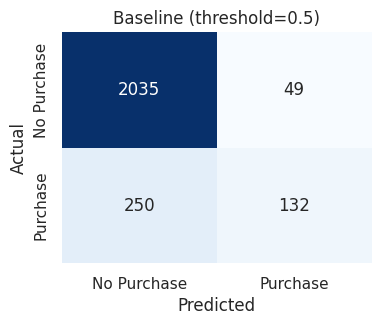

              precision    recall  f1-score   support

 No Purchase       0.89      0.98      0.93      2084
    Purchase       0.73      0.35      0.47       382

    accuracy                           0.88      2466
   macro avg       0.81      0.66      0.70      2466
weighted avg       0.87      0.88      0.86      2466



In [ ]:
# TODO: Evaluate baseline model using evaluate_predictions.
# TODO: Show confusion matrix.
# TODO: Print classification_report.

results = []

# Evaluate and store results
baseline_results = evaluate_predictions(y_test, y_pred_baseline, "Baseline")
results.append(baseline_results)

# Confusion matrix
show_confusion_matrix(y_test, y_pred_baseline, "Baseline (threshold=0.5)")

# Full classification report
print(classification_report(y_test, y_pred_baseline, target_names=["No Purchase", "Purchase"]))

## 9. Threshold Tuning

Logistic regression gives probabilities:

\[
P(y=1|x)
\]

The default threshold is usually:

\[
\text{predict purchase if } P(y=1|x) \geq 0.5
\]

But in business problems, we may change the threshold depending on whether we care more about precision or recall.

Try thresholds:

```python
[0.20, 0.30, 0.40, 0.50, 0.60]
```

In [ ]:
# TODO: Get predicted probabilities for the positive class using baseline_model.predict_proba(X_test)[:, 1].
# TODO: For each threshold, convert probabilities into class predictions.
# TODO: Create a threshold comparison table with accuracy, precision, recall, and F1.

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

# Get predicted probabilities for the positive class (Purchase)
y_proba_baseline = baseline_model.predict_proba(X_test)[:, 1]

# Try different thresholds and collect metrics
threshold_results = []

for thresh in thresholds:
    # Convert probabilities to class predictions using the threshold
    y_pred_thresh = (y_proba_baseline >= thresh).astype(int)

    # Evaluate
    metrics = evaluate_predictions(y_test, y_pred_thresh, f"Threshold={thresh}")
    metrics["threshold"] = thresh
    threshold_results.append(metrics)

# Show comparison table
threshold_df = pd.DataFrame(threshold_results)
print(threshold_df[["threshold", "accuracy", "precision", "recall", "f1"]])

   threshold  accuracy  precision    recall        f1
0        0.2  0.863341   0.548180  0.670157  0.603062
1        0.3  0.890511   0.689189  0.534031  0.601770
2        0.4  0.885239   0.712446  0.434555  0.539837
3        0.5  0.878751   0.729282  0.345550  0.468917
4        0.6  0.877129   0.780142  0.287958  0.420650


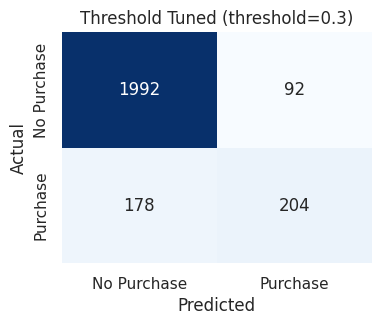

In [ ]:
# TODO: Choose one threshold based on your business reasoning.
# Store it in selected_threshold.
# Example: selected_threshold = 0.30

selected_threshold = None

# TODO: Create y_pred_threshold using selected_threshold.
# TODO: Evaluate and append result to results.
# TODO: Show confusion matrix.

# Choose threshold - lower threshold catches more buyers (higher recall)
selected_threshold = 0.30

# Predict using selected threshold
y_pred_threshold = (y_proba_baseline >= selected_threshold).astype(int)

# Evaluate and store
threshold_result = evaluate_predictions(y_test, y_pred_threshold, "Threshold Tuned")
results.append(threshold_result)

# Confusion matrix
show_confusion_matrix(y_test, y_pred_threshold, f"Threshold Tuned (threshold={selected_threshold})")

### Question 3

What happens to precision and recall when you reduce the threshold?

Why does this happen?

Write your answer here:

When the threshold is reduced:

- Recall goes UP — model shows more actual buyers.
- Precision goes DOWN — model also flags more non-buyers as buyers.

This happens because the threshold controls how easy it is to be predicted as a buyer. Repeating the doctor's example here. Assume a doctor is screening for a disease:

- Strict threshold (0.50): Only includes patients who are clearly sick. This may miss some early-stage patients.
- Relaxed threshold (0.30): Include anyone who shows even mild symptoms. This catches more sick patients, but may also send some patients for unnecessary tests.

However, missing a patient at early stage is more risky, so a relaxed threshold is a better option.

## 10. Class-Weighted Logistic Regression

Train logistic regression with:

```python
class_weight="balanced"
```

This gives more importance to the minority class during training.

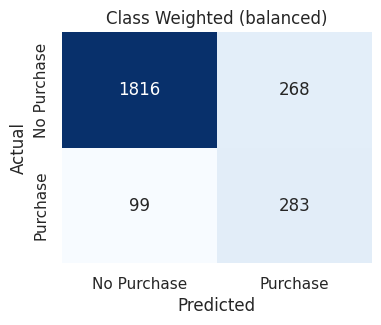

In [ ]:
weighted_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# TODO: Fit weighted_model on X_train and y_train.
weighted_model.fit(X_train, y_train)

# TODO: Predict on X_test and store predictions in y_pred_weighted.
y_pred_weighted = weighted_model.predict(X_test)

# TODO: Evaluate and append result to results.
weighted_result = evaluate_predictions(y_test, y_pred_weighted, "Class Weighted")
results.append(weighted_result)

# TODO: Show confusion matrix.
show_confusion_matrix(y_test, y_pred_weighted, "Class Weighted (balanced)")

### Question 4

How did `class_weight="balanced"` change recall and precision compared to the baseline model?

Write your answer here:

- Recall went up - the class_weight="balanced" shows more predictions for purchase.
- Precision goes down - the class_weight="balanced" model flags more non-buyers as buyers.

## 11. SMOTE + Logistic Regression

SMOTE creates synthetic minority-class examples.

Important rule:

> Apply SMOTE only on the training data, never on the test data.

For this assignment, first transform the train and test data using the preprocessor, then apply SMOTE only on the transformed training data.

In [ ]:
# TODO: Fit the preprocessor on the training features.
# TODO: Use the fitted preprocessor to transform both training and test features.
#
# Hint:
# - The training set should be used to learn scaling and encoding rules.
# - The test set should only be transformed using those already-learned rules.
# - You will need one processed training feature matrix and one processed test feature matrix.

preprocessor.fit(X_train)
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
# TODO: Apply SMOTE only on the processed training data and y_train.
#
# Hint:
# - Create a SMOTE object with RANDOM_STATE.
# - Use the SMOTE resampling method on training data only.
# - Store the resampled features and resampled target separately.
# - Do not apply SMOTE on the test data.

smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

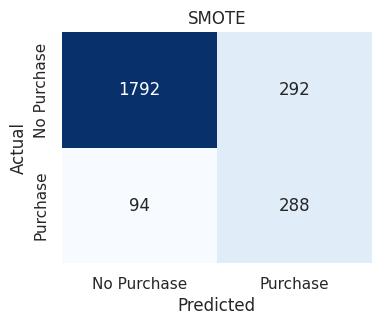

In [ ]:
# TODO: Train LogisticRegression on X_train_smote and y_train_smote.
lr_smote = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_smote.fit(X_train_smote, y_train_smote)

# TODO: Predict on X_test_processed.
y_pred_smote = lr_smote.predict(X_test_processed)

# TODO: Evaluate and append result to results.
results.append(evaluate_predictions(y_test, y_pred_smote, "SMOTE"))

# TODO: Show confusion matrix.
show_confusion_matrix(y_test, y_pred_smote, "SMOTE")

### Question 5

Why should SMOTE be applied only on the training data?

Write your answer here:

SMOTE should be applied only on the training data because:

- SMOTE is a training technique, and not a data transformation. Applying it to the test set would make our evaluation metrics meaningless.

- SMOTE creates fake data to help the model learn. If we add this fake data to the test set, we are no longer testing on real data.

The test set is for checking how well the model works on real data. We can train on fake and real data, but we must test on real data only.

## 12. Final Comparison

Create a final comparison table for all methods:

1. Baseline Logistic Regression
2. Threshold-Tuned Logistic Regression
3. Class-Weighted Logistic Regression
4. SMOTE + Logistic Regression

In [ ]:
# TODO: Convert results into a DataFrame and sort/format it clearly.

# Convert results list into a DataFrame
results_df = pd.DataFrame(results)

# Round numeric columns to 4 decimal places
results_df = results_df.round(4)

# Display the comparison table
print("=" * 65)
print("        FINAL MODEL COMPARISON — ALL METHODS")
print("=" * 65)
print(results_df.to_string(index=False))
print("=" * 65)

results_df.style.highlight_max(axis=0, color="lightgreen")

        FINAL MODEL COMPARISON — ALL METHODS
          model  accuracy  precision  recall     f1
       Baseline    0.8788     0.7293  0.3455 0.4689
Threshold Tuned    0.8905     0.6892  0.5340 0.6018
 Class Weighted    0.8512     0.5136  0.7408 0.6066
          SMOTE    0.8435     0.4966  0.7539 0.5988


,model,accuracy,precision,recall,f1
0,Baseline,0.878800,0.729300,0.345500,0.468900
1,Threshold Tuned,0.890500,0.689200,0.534000,0.601800
2,Class Weighted,0.851200,0.513600,0.740800,0.606600
3,SMOTE,0.843500,0.496600,0.753900,0.598800


## 13. Business Decision Questions

Answer these briefly.

### Question 6

If discount cost is high and the company wants to avoid showing offers to too many non-buyers, should it prioritize precision or recall?

Answer:

- The company should prioritize precision. If discount cost is high, showing offers to non-buyers wastes money. Target only users who are very likely to buy, even if that means missing some real buyers. High precision = fewer wasted discounts = lower cost.

### Question 7

If missing a potential buyer is very costly, should the company prioritize precision or recall?

Answer:

- In this case, prioritize recall. If missing a buyer is costly, one must show the offer to everyone likely to buy, even if some non-buyers get it too. High recall = fewer missed buyers = more revenue captured.

### Question 8

Which model/method would you recommend for this business problem?

Mention:

- The model/method you selected
- The metric you prioritized
- Why this decision makes business sense

Answer:

- For this business problem I would recommend **SMOTE + Logistic Regression**.
- The prioritized metric would be **recall**.
- The dataset is heavily imbalanced (~85% non-buyers), which causes a default model to ignore the minority class (buyers). SMOTE corrects this by generating fake buyer examples during training, giving the model a balanced view. Since the goal is to identify potential buyers for discount offers, missing a real buyer is more costly. SMOTE achieves the best recall without manipulating the test data, therefore it seems to be a better option.

## Submission Checklist

Submit your completed notebook with:

- All code cells executed
- Final comparison table
- Confusion matrices for each method
- Answers to all business questions
- A short final recommendation